# AI-Driven Spare-Parts Inventory Optimization at Honeywell Aerospace
## Multi-Objective Optimization Analysis

**Student Name:** Christelle Jean   
**Professor:** Alex Shaw   
**Target Company/Industry:** Honeywell Aerospace / Aerospace Supply Chain Management  
**Problem:** Selecting safety-stock levels and reorder quantities for critical aerospace spare parts.  
**Objectives:** Minimize expected annual inventory cost vs. maximize immediate part availability.         
**Date:** 11/14/2026


## Project Overview

This project examines how Honeywell Aerospace could balance inventory cost with the availability of critical spare parts. Keeping more inventory can prevent maintenance delays, but it also ties up cash and increases storage and obsolescence costs. I will test different combinations of safety-stock levels and reorder quantities and use Pareto analysis to identify the efficient policies. The goal is to show which inventory choices offer meaningful tradeoffs and which choices are inefficient.

# Section 1: Data Acquisition

## Synthetic Data Approach

Honeywell does not publish its part-level demand, inventory, lead-time, or cost records. I therefore created a synthetic dataset for one representative high-criticality aerospace spare part. The dataset compares 100 policies formed from ten safety-stock levels and ten reorder quantities.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Create the required project folders if they do not already exist.
DATA_DIR = Path("data")
IMAGE_DIR = Path("images")
DATA_DIR.mkdir(exist_ok=True)
IMAGE_DIR.mkdir(exist_ok=True)

# A fixed seed makes the synthetic results reproducible.
RANDOM_SEED = 20261115
rng = np.random.default_rng(RANDOM_SEED)

# Decision-variable choices
safety_stock_levels = range(5, 51, 5)
reorder_quantities = range(10, 101, 10)

# Assumptions for one representative critical aerospace spare part
annual_demand = 120
demand_variability_cv = 0.75
supplier_lead_time_days = 45
part_criticality = "High"
unit_cost = 12_000
annual_holding_rate = 0.20
ordering_cost_per_order = 1_500
stockout_penalty_per_unit = 6_000
emergency_premium_per_unit = 2_000
obsolescence_rate = 0.03
storage_per_unit = 1.8
downtime_hours_per_stockout = 12

records = []
policy_number = 1

for safety_stock in safety_stock_levels:
    for reorder_quantity in reorder_quantities:
        # Expected demand during supplier lead time plus safety stock
        lead_time_demand = annual_demand * supplier_lead_time_days / 365
        reorder_point = lead_time_demand + safety_stock

        # Average inventory under a basic continuous-review policy
        average_inventory = safety_stock + (reorder_quantity / 2)
        annual_orders = annual_demand / reorder_quantity

        # Safety stock has the strongest effect on availability.
        # Reorder quantity has a smaller effect, and both have diminishing returns.
        random_variation = rng.normal(0, 0.25)
        fill_rate = (
            82
            + 15.5 * (1 - np.exp(-safety_stock / 18))
            + 2.0 * (1 - np.exp(-reorder_quantity / 45))
            + random_variation
        )
        fill_rate = float(np.clip(fill_rate, 0, 99.6))

        expected_stockouts = annual_demand * (1 - fill_rate / 100)

        # Annual inventory-policy costs
        holding_cost = (
            average_inventory * unit_cost * annual_holding_rate
        )
        ordering_cost = annual_orders * ordering_cost_per_order
        shortage_cost = expected_stockouts * stockout_penalty_per_unit
        emergency_order_cost = (
            expected_stockouts * emergency_premium_per_unit
        )
        obsolescence_cost = (
            average_inventory * unit_cost * obsolescence_rate
        )

        annual_inventory_cost = (
            holding_cost
            + ordering_cost
            + shortage_cost
            + emergency_order_cost
            + obsolescence_cost
        )

        records.append(
            {
                "policy_id": f"P{policy_number:03d}",
                "safety_stock_units": safety_stock,
                "reorder_quantity_units": reorder_quantity,
                "reorder_point_units": round(reorder_point, 1),
                "annual_demand_units": annual_demand,
                "demand_variability_cv": demand_variability_cv,
                "supplier_lead_time_days": supplier_lead_time_days,
                "part_criticality": part_criticality,
                "unit_cost_usd": unit_cost,
                "annual_holding_rate": annual_holding_rate,
                "ordering_cost_per_order_usd": ordering_cost_per_order,
                "stockout_penalty_per_unit_usd": stockout_penalty_per_unit,
                "emergency_premium_per_unit_usd": emergency_premium_per_unit,
                "obsolescence_rate": obsolescence_rate,
                "average_inventory_units": round(average_inventory, 1),
                "annual_orders": round(annual_orders, 2),
                "expected_stockout_units": round(expected_stockouts, 2),
                "holding_cost_usd": round(holding_cost, 2),
                "ordering_cost_usd": round(ordering_cost, 2),
                "shortage_cost_usd": round(shortage_cost, 2),
                "emergency_order_cost_usd": round(
                    emergency_order_cost, 2
                ),
                "obsolescence_cost_usd": round(
                    obsolescence_cost, 2
                ),
                "annual_inventory_cost_usd": round(
                    annual_inventory_cost, 2
                ),
                "immediate_fill_rate_pct": round(fill_rate, 2),
                "storage_used_cubic_feet": round(
                    average_inventory * storage_per_unit, 1
                ),
                "expected_downtime_hours": round(
                    expected_stockouts * downtime_hours_per_stockout, 1
                ),
            }
        )

        policy_number += 1

df = pd.DataFrame(records)

# Save the dataset in the repository's data folder.
data_path = DATA_DIR / "synthetic_inventory_policies.csv"
df.to_csv(data_path, index=False)

# Basic generation checks
assert len(df) == 100
assert df[
    ["safety_stock_units", "reorder_quantity_units"]
].duplicated().sum() == 0
assert df["immediate_fill_rate_pct"].between(0, 100).all()

print("Synthetic dataset created successfully.")
print(f"File: {data_path}")
print(f"Rows: {len(df)}")
print(f"Columns: {len(df.columns)}")

df.head()

Synthetic dataset created successfully.
File: data\synthetic_inventory_policies.csv
Rows: 100
Columns: 26


,policy_id,safety_stock_units,reorder_quantity_units,reorder_point_units,annual_demand_units,demand_variability_cv,supplier_lead_time_days,part_criticality,unit_cost_usd,annual_holding_rate,...,expected_stockout_units,holding_cost_usd,ordering_cost_usd,shortage_cost_usd,emergency_order_cost_usd,obsolescence_cost_usd,annual_inventory_cost_usd,immediate_fill_rate_pct,storage_used_cubic_feet,expected_downtime_hours
0,P001,5,10,19.8,120,0.75,45,High,12000,0.2,...,16.61,24000.0,18000.0,99632.54,33210.85,3600.0,178443.39,86.16,18.0,199.3
1,P002,5,20,19.8,120,0.75,45,High,12000,0.2,...,16.29,36000.0,9000.0,97752.22,32584.07,5400.0,180736.29,86.42,27.0,195.5
2,P003,5,30,19.8,120,0.75,45,High,12000,0.2,...,16.35,48000.0,6000.0,98120.63,32706.88,7200.0,192027.51,86.37,36.0,196.2
3,P004,5,40,19.8,120,0.75,45,High,12000,0.2,...,15.83,60000.0,4500.0,94973.47,31657.82,9000.0,200131.29,86.81,45.0,189.9
4,P005,5,50,19.8,120,0.75,45,High,12000,0.2,...,15.72,72000.0,3600.0,94321.50,31440.50,10800.0,212162.01,86.90,54.0,188.6


# Section 2: Data Exploration

## Data Quality and Validation

I reloaded the saved CSV to confirm that the analysis does not depend on data remaining in memory. I checked the dataset for missing values, duplicate policies, incorrect data types, unrealistic values, and incomplete decision-variable combinations.

In [2]:
# Reload the saved dataset to test reproducibility.
data_path = Path("data") / "synthetic_inventory_policies.csv"
df = pd.read_csv(data_path)

# Columns needed for the optimization analysis
required_columns = [
    "policy_id",
    "safety_stock_units",
    "reorder_quantity_units",
    "annual_inventory_cost_usd",
    "immediate_fill_rate_pct",
]

missing_columns = [
    column for column in required_columns
    if column not in df.columns
]

if missing_columns:
    raise ValueError(f"Required columns are missing: {missing_columns}")

# Main data-quality measurements
duplicate_policies = df[
    ["safety_stock_units", "reorder_quantity_units"]
].duplicated().sum()

quality_summary = pd.DataFrame(
    {
        "Quality Check": [
            "Total rows",
            "Total columns",
            "Missing values",
            "Duplicate policy combinations",
            "Unique policy IDs",
            "Safety-stock levels",
            "Reorder-quantity levels",
        ],
        "Result": [
            len(df),
            len(df.columns),
            int(df.isna().sum().sum()),
            int(duplicate_policies),
            df["policy_id"].nunique(),
            df["safety_stock_units"].nunique(),
            df["reorder_quantity_units"].nunique(),
        ],
    }
)

print("Data quality summary")
display(quality_summary)

print("Column data types")
display(df.dtypes.to_frame(name="Data Type"))

# Statistical summary for the main decision and outcome variables
analysis_columns = [
    "safety_stock_units",
    "reorder_quantity_units",
    "reorder_point_units",
    "average_inventory_units",
    "annual_orders",
    "expected_stockout_units",
    "annual_inventory_cost_usd",
    "immediate_fill_rate_pct",
    "storage_used_cubic_feet",
    "expected_downtime_hours",
]

print("Main variable statistics")
display(df[analysis_columns].describe().T.round(2))

# Check important ranges and business relationships.
print(
    f"Safety-stock range: "
    f"{df['safety_stock_units'].min()} to "
    f"{df['safety_stock_units'].max()} units"
)
print(
    f"Reorder-quantity range: "
    f"{df['reorder_quantity_units'].min()} to "
    f"{df['reorder_quantity_units'].max()} units"
)
print(
    f"Annual inventory-cost range: "
    f"${df['annual_inventory_cost_usd'].min():,.2f} to "
    f"${df['annual_inventory_cost_usd'].max():,.2f}"
)
print(
    f"Immediate fill-rate range: "
    f"{df['immediate_fill_rate_pct'].min():.2f}% to "
    f"{df['immediate_fill_rate_pct'].max():.2f}%"
)

objective_correlation = df[
    "annual_inventory_cost_usd"
].corr(df["immediate_fill_rate_pct"])

print(
    f"Cost and availability correlation: "
    f"{objective_correlation:.3f}"
)
print(
    "A positive correlation supports the tradeoff: "
    "higher availability generally requires more inventory cost."
)

# Final validation tests
assert len(df) == 100
assert df["policy_id"].is_unique
assert df.isna().sum().sum() == 0
assert duplicate_policies == 0
assert df["annual_inventory_cost_usd"].gt(0).all()
assert df["immediate_fill_rate_pct"].between(0, 100).all()
assert df["expected_stockout_units"].ge(0).all()
assert (
    df["safety_stock_units"].nunique()
    * df["reorder_quantity_units"].nunique()
    == len(df)
)

print("All data validation checks passed.")

Data quality summary


,Quality Check,Result
0,Total rows,100
1,Total columns,26
2,Missing values,0
3,Duplicate policy combinations,0
4,Unique policy IDs,100
5,Safety-stock levels,10
6,Reorder-quantity levels,10


Column data types


,Data Type
policy_id,str
safety_stock_units,int64
reorder_quantity_units,int64
reorder_point_units,float64
annual_demand_units,int64
demand_variability_cv,float64
supplier_lead_time_days,int64
part_criticality,str
unit_cost_usd,int64
annual_holding_rate,float64


Main variable statistics


,count,mean,std,min,25%,50%,75%,max
safety_stock_units,100.0,27.50,14.43,5.00,15.00,27.50,40.00,50.00
reorder_quantity_units,100.0,55.00,28.87,10.00,30.00,55.00,80.00,100.00
reorder_point_units,100.0,42.30,14.43,19.80,29.80,42.30,54.80,64.80
average_inventory_units,100.0,55.00,20.41,10.00,40.00,55.00,70.00,100.00
annual_orders,100.0,3.51,3.17,1.20,1.50,2.20,4.00,12.00
expected_stockout_units,100.0,6.92,4.24,1.69,3.60,5.60,9.57,16.61
annual_inventory_cost_usd,100.0,212442.52,34933.24,155999.75,184844.74,208097.98,240324.99,293009.75
immediate_fill_rate_pct,100.0,94.23,3.53,86.16,92.03,95.34,97.00,98.59
storage_used_cubic_feet,100.0,99.00,36.74,18.00,72.00,99.00,126.00,180.00
expected_downtime_hours,100.0,83.05,50.85,20.20,43.18,67.20,114.82,199.30


Safety-stock range: 5 to 50 units
Reorder-quantity range: 10 to 100 units
Annual inventory-cost range: $155,999.75 to $293,009.75
Immediate fill-rate range: 86.16% to 98.59%
Cost and availability correlation: 0.220
A positive correlation supports the tradeoff: higher availability generally requires more inventory cost.
All data validation checks passed.


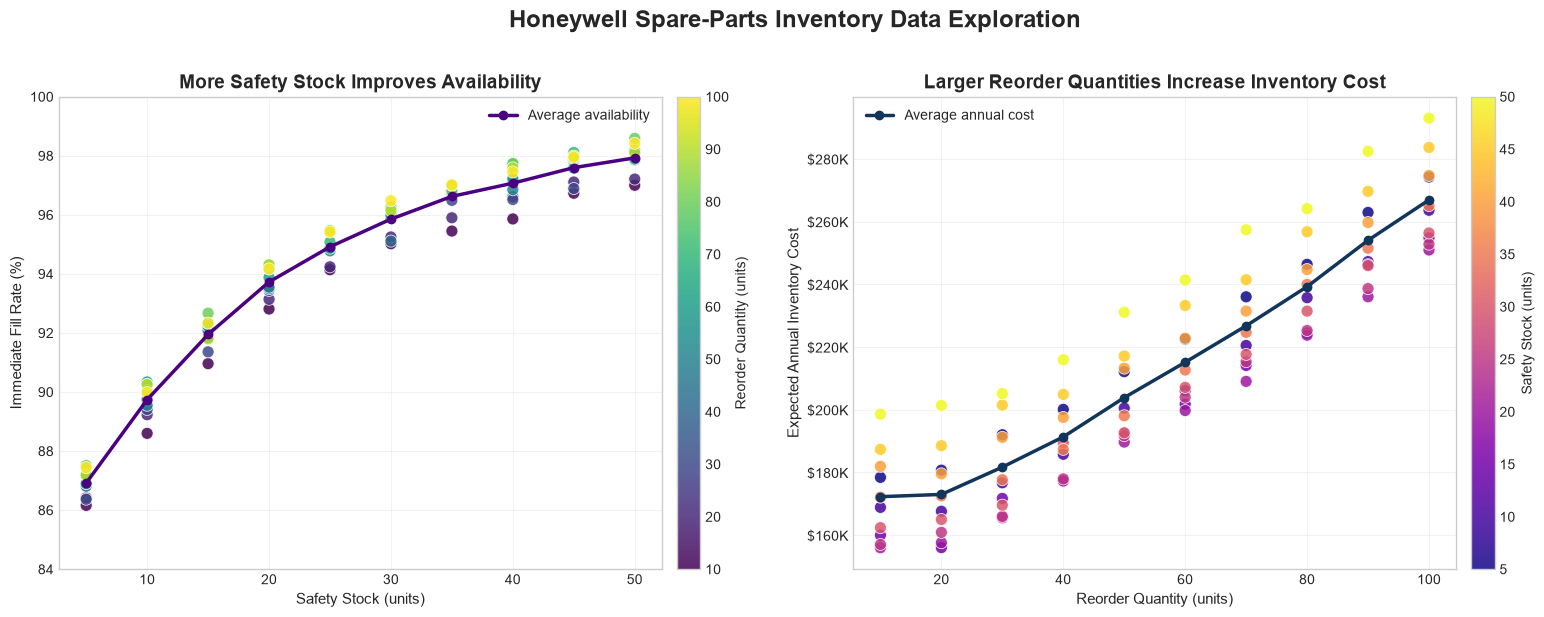

In [4]:
from matplotlib.ticker import FuncFormatter

plt.style.use("seaborn-v0_8-whitegrid")

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Panel 1: Safety stock and availability
availability_plot = axes[0].scatter(
    df["safety_stock_units"],
    df["immediate_fill_rate_pct"],
    c=df["reorder_quantity_units"],
    cmap="viridis",
    s=75,
    alpha=0.85,
    edgecolors="white",
    linewidth=0.6,
)

availability_trend = (
    df.groupby("safety_stock_units")["immediate_fill_rate_pct"]
    .mean()
)

axes[0].plot(
    availability_trend.index,
    availability_trend.values,
    color="#4B0082",
    linewidth=2.5,
    marker="o",
    label="Average availability",
)

axes[0].set_title(
    "More Safety Stock Improves Availability",
    fontsize=14,
    fontweight="bold",
)
axes[0].set_xlabel("Safety Stock (units)", fontsize=11)
axes[0].set_ylabel("Immediate Fill Rate (%)", fontsize=11)
axes[0].set_ylim(84, 100)
axes[0].legend()
axes[0].grid(alpha=0.25)

colorbar1 = fig.colorbar(
    availability_plot,
    ax=axes[0],
    pad=0.02,
)
colorbar1.set_label("Reorder Quantity (units)")

# Panel 2: Reorder quantity and annual cost
cost_plot = axes[1].scatter(
    df["reorder_quantity_units"],
    df["annual_inventory_cost_usd"],
    c=df["safety_stock_units"],
    cmap="plasma",
    s=75,
    alpha=0.85,
    edgecolors="white",
    linewidth=0.6,
)

cost_trend = (
    df.groupby("reorder_quantity_units")[
        "annual_inventory_cost_usd"
    ]
    .mean()
)

axes[1].plot(
    cost_trend.index,
    cost_trend.values,
    color="#12355B",
    linewidth=2.5,
    marker="o",
    label="Average annual cost",
)

axes[1].set_title(
    "Larger Reorder Quantities Increase Inventory Cost",
    fontsize=14,
    fontweight="bold",
)
axes[1].set_xlabel("Reorder Quantity (units)", fontsize=11)
axes[1].set_ylabel("Expected Annual Inventory Cost", fontsize=11)
axes[1].yaxis.set_major_formatter(
    FuncFormatter(lambda value, position: f"${value / 1000:.0f}K")
)
axes[1].legend()
axes[1].grid(alpha=0.25)

colorbar2 = fig.colorbar(
    cost_plot,
    ax=axes[1],
    pad=0.02,
)
colorbar2.set_label("Safety Stock (units)")

fig.suptitle(
    "Honeywell Spare-Parts Inventory Data Exploration",
    fontsize=17,
    fontweight="bold",
    y=1.02,
)

plt.tight_layout()
plt.savefig(
    "images/data_exploration.png",
    dpi=300,
    bbox_inches="tight",
)
plt.show()


### Exploration Findings

The dataset passed all quality checks and contains the full set of 100 inventory policies without missing or duplicate records. Annual inventory cost ranges from about $156,000 to $293,000, while immediate fill rate ranges from 86.16% to 98.59%. The results show that increasing safety stock improves availability, while larger reorder quantities generally increase annual cost because more inventory is stored. The positive correlation of 0.220 between cost and availability supports the expected tradeoff: improving part availability usually requires additional spending.

# Section 3: Pareto Frontier Calculation

## Pareto Frontier Method

A policy is dominated when another policy has an equal or lower annual cost and an equal or higher fill rate, with at least one result being strictly better. A Pareto-efficient policy cannot improve one objective without sacrificing the other. Because cost should decrease while availability should increase, the function handles the two objective directions separately.

In [6]:
def is_pareto_optimal(
    idx,
    data,
    objective_directions,
):
    """
    Determine whether one row is Pareto efficient.

    Parameters
    ----------
    idx : int
        Index of the policy being evaluated.
    data : pandas.DataFrame
        Dataset containing all policy choices.
    objective_directions : dict
        Objective columns mapped to either "min" or "max".

    Returns
    -------
    bool
        True when no other policy dominates the selected policy.
    """
    if idx not in data.index:
        raise KeyError(f"Index {idx} is not in the dataset.")

    valid_directions = {"min", "max"}

    if not set(objective_directions.values()).issubset(
        valid_directions
    ):
        raise ValueError(
            "Each objective direction must be 'min' or 'max'."
        )

    objective_columns = list(objective_directions.keys())

    if data[objective_columns].isna().any().any():
        raise ValueError(
            "Objective columns cannot contain missing values."
        )

    # Convert all objectives to a higher-is-better direction.
    direction_signs = np.array(
        [
            -1 if direction == "min" else 1
            for direction in objective_directions.values()
        ]
    )

    all_values = data[objective_columns].to_numpy(
        dtype=float
    )
    current_values = data.loc[
        idx, objective_columns
    ].to_numpy(dtype=float)

    adjusted_values = all_values * direction_signs
    adjusted_current = current_values * direction_signs

    # Another policy dominates the current one when it is at
    # least as good on every objective and better on at least one.
    dominates_current = (
        np.all(
            adjusted_values >= adjusted_current,
            axis=1,
        )
        & np.any(
            adjusted_values > adjusted_current,
            axis=1,
        )
    )

    return not dominates_current.any()


OBJECTIVE_DIRECTIONS = {
    "annual_inventory_cost_usd": "min",
    "immediate_fill_rate_pct": "max",
}

df["is_pareto_optimal"] = df.index.map(
    lambda idx: is_pareto_optimal(
        idx,
        df,
        OBJECTIVE_DIRECTIONS,
    )
)

pareto_df = df[df["is_pareto_optimal"]].copy()
dominated_df = df[~df["is_pareto_optimal"]].copy()

pareto_df = pareto_df.sort_values(
    "annual_inventory_cost_usd"
)

# Save the classification for later analysis.
classified_path = (
    Path("data") / "inventory_policies_with_pareto.csv"
)
df.to_csv(classified_path, index=False)

pareto_summary = pd.DataFrame(
    {
        "Classification": [
            "All policies",
            "Pareto-efficient policies",
            "Dominated policies",
        ],
        "Count": [
            len(df),
            len(pareto_df),
            len(dominated_df),
        ],
        "Percentage": [
            100.0,
            100 * len(pareto_df) / len(df),
            100 * len(dominated_df) / len(df),
        ],
    }
)

print("Pareto frontier results")

summary_display = pareto_summary.copy()
summary_display["Percentage"] = (
    summary_display["Percentage"]
    .map(lambda value: f"{value:.1f}%")
)

display(summary_display)

print("Efficient inventory policies")

frontier_display = pareto_df[
    [
        "policy_id",
        "safety_stock_units",
        "reorder_quantity_units",
        "annual_inventory_cost_usd",
        "immediate_fill_rate_pct",
    ]
].reset_index(drop=True).copy()

frontier_display["annual_inventory_cost_usd"] = (
    frontier_display["annual_inventory_cost_usd"]
    .map(lambda value: f"${value:,.2f}")
)

frontier_display["immediate_fill_rate_pct"] = (
    frontier_display["immediate_fill_rate_pct"]
    .map(lambda value: f"{value:.2f}%")
)

display(frontier_display)

Pareto frontier results


,Classification,Count,Percentage
0,All policies,100,100.0%
1,Pareto-efficient policies,17,17.0%
2,Dominated policies,83,83.0%


Efficient inventory policies


,policy_id,safety_stock_units,reorder_quantity_units,annual_inventory_cost_usd,immediate_fill_rate_pct
0,P031,20,10,"$155,999.75",92.81%
1,P041,25,10,"$157,046.61",94.14%
2,P042,25,20,"$160,909.12",94.24%
3,P051,30,10,"$162,410.40",95.02%
4,P052,30,20,"$165,005.96",95.25%
5,P053,30,30,"$169,580.61",95.90%
6,P063,35,30,"$177,703.48",96.49%
7,P072,40,20,"$179,566.95",96.61%
8,P064,35,40,"$187,365.08",96.76%
9,P082,45,20,"$188,544.36",97.11%


### Pareto Frontier Findings

The analysis found 17 Pareto-efficient policies and 83 dominated policies. This means 83% of the original choices can be removed because another policy offers a lower cost, a higher fill rate, or both. On the efficient frontier, annual cost ranges from about $156,000 to $264,000 while fill rate increases from 92.81% to 98.59%. These remaining policies represent real tradeoffs because improving availability beyond one point requires accepting a higher annual cost.

## Inefficient Policy Analysis

A dominated policy should not be selected because at least one efficient policy can reduce its cost, improve its fill rate, or improve both. The following analysis finds an efficient replacement for every dominated policy and highlights three of the largest improvement opportunities.

In [8]:
COST_COLUMN = "annual_inventory_cost_usd"
AVAILABILITY_COLUMN = "immediate_fill_rate_pct"

comparison_records = []

for _, dominated_policy in dominated_df.iterrows():
    # Find efficient policies that are no more expensive and
    # provide at least the same availability.
    better_options = pareto_df[
        (pareto_df[COST_COLUMN]
         <= dominated_policy[COST_COLUMN])
        & (pareto_df[AVAILABILITY_COLUMN]
           >= dominated_policy[AVAILABILITY_COLUMN])
        & (
            (pareto_df[COST_COLUMN]
             < dominated_policy[COST_COLUMN])
            | (pareto_df[AVAILABILITY_COLUMN]
               > dominated_policy[AVAILABILITY_COLUMN])
        )
    ].copy()

    if better_options.empty:
        continue

    better_options["cost_savings_pct"] = (
        (
            dominated_policy[COST_COLUMN]
            - better_options[COST_COLUMN]
        )
        / dominated_policy[COST_COLUMN]
        * 100
    )

    better_options["availability_gain"] = (
        better_options[AVAILABILITY_COLUMN]
        - dominated_policy[AVAILABILITY_COLUMN]
    )

    # Give equal attention to percentage cost savings and
    # percentage-point availability improvement.
    better_options["improvement_score"] = (
        better_options["cost_savings_pct"]
        + better_options["availability_gain"]
    )

    best_alternative = better_options.loc[
        better_options["improvement_score"].idxmax()
    ]

    comparison_records.append(
        {
            "dominated_policy": dominated_policy["policy_id"],
            "dominated_safety_stock": dominated_policy[
                "safety_stock_units"
            ],
            "dominated_reorder_quantity": dominated_policy[
                "reorder_quantity_units"
            ],
            "dominated_cost": dominated_policy[COST_COLUMN],
            "dominated_fill_rate": dominated_policy[
                AVAILABILITY_COLUMN
            ],
            "better_policy": best_alternative["policy_id"],
            "better_safety_stock": best_alternative[
                "safety_stock_units"
            ],
            "better_reorder_quantity": best_alternative[
                "reorder_quantity_units"
            ],
            "better_cost": best_alternative[COST_COLUMN],
            "better_fill_rate": best_alternative[
                AVAILABILITY_COLUMN
            ],
            "annual_cost_savings": (
                dominated_policy[COST_COLUMN]
                - best_alternative[COST_COLUMN]
            ),
            "cost_savings_pct": best_alternative[
                "cost_savings_pct"
            ],
            "fill_rate_gain": best_alternative[
                "availability_gain"
            ],
            "improvement_score": best_alternative[
                "improvement_score"
            ],
        }
    )

dominance_comparisons = pd.DataFrame(
    comparison_records
).sort_values(
    "improvement_score",
    ascending=False,
)

top_examples = dominance_comparisons.head(3).copy()

# Save the numeric results before formatting them for display.
top_examples.to_csv(
    "data/dominated_policy_examples.csv",
    index=False,
)

examples_display = top_examples[
    [
        "dominated_policy",
        "dominated_safety_stock",
        "dominated_reorder_quantity",
        "dominated_cost",
        "dominated_fill_rate",
        "better_policy",
        "better_safety_stock",
        "better_reorder_quantity",
        "better_cost",
        "better_fill_rate",
        "annual_cost_savings",
        "fill_rate_gain",
    ]
].copy()

examples_display.columns = [
    "Dominated Policy",
    "Old Safety Stock",
    "Old Reorder Qty",
    "Old Annual Cost",
    "Old Fill Rate",
    "Better Policy",
    "New Safety Stock",
    "New Reorder Qty",
    "New Annual Cost",
    "New Fill Rate",
    "Annual Savings",
    "Fill-Rate Gain",
]

for column in [
    "Old Annual Cost",
    "New Annual Cost",
    "Annual Savings",
]:
    examples_display[column] = examples_display[column].map(
        lambda value: f"${value:,.2f}"
    )

for column in [
    "Old Fill Rate",
    "New Fill Rate",
]:
    examples_display[column] = examples_display[column].map(
        lambda value: f"{value:.2f}%"
    )

examples_display["Fill-Rate Gain"] = (
    examples_display["Fill-Rate Gain"].map(
        lambda value: f"{value:.2f} points"
    )
)

print("Dominated policies and better alternatives")
display(examples_display)

# Normalize the objectives before comparing combined performance.
analysis_df = df.copy()

cost_range = (
    analysis_df[COST_COLUMN].max()
    - analysis_df[COST_COLUMN].min()
)
availability_range = (
    analysis_df[AVAILABILITY_COLUMN].max()
    - analysis_df[AVAILABILITY_COLUMN].min()
)

analysis_df["cost_efficiency_score"] = (
    (
        analysis_df[COST_COLUMN].max()
        - analysis_df[COST_COLUMN]
    )
    / cost_range
    * 100
)

analysis_df["availability_score"] = (
    (
        analysis_df[AVAILABILITY_COLUMN]
        - analysis_df[AVAILABILITY_COLUMN].min()
    )
    / availability_range
    * 100
)

analysis_df["combined_score"] = (
    analysis_df["cost_efficiency_score"]
    + analysis_df["availability_score"]
) / 2

best_dominated_idx = analysis_df.loc[
    dominated_df.index,
    "combined_score",
].idxmax()

lowest_scoring_pareto_idx = analysis_df.loc[
    pareto_df.index,
    "combined_score",
].idxmin()

score_comparison = pd.DataFrame(
    [
        {
            "Policy Type": "Best combined-score dominated policy",
            "Policy": analysis_df.loc[
                best_dominated_idx, "policy_id"
            ],
            "Annual Cost": analysis_df.loc[
                best_dominated_idx, COST_COLUMN
            ],
            "Fill Rate": analysis_df.loc[
                best_dominated_idx, AVAILABILITY_COLUMN
            ],
            "Combined Score": analysis_df.loc[
                best_dominated_idx, "combined_score"
            ],
        },
        {
            "Policy Type": "Lowest combined-score efficient policy",
            "Policy": analysis_df.loc[
                lowest_scoring_pareto_idx, "policy_id"
            ],
            "Annual Cost": analysis_df.loc[
                lowest_scoring_pareto_idx, COST_COLUMN
            ],
            "Fill Rate": analysis_df.loc[
                lowest_scoring_pareto_idx,
                AVAILABILITY_COLUMN,
            ],
            "Combined Score": analysis_df.loc[
                lowest_scoring_pareto_idx,
                "combined_score",
            ],
        },
    ]
)

score_display = score_comparison.copy()
score_display["Annual Cost"] = score_display[
    "Annual Cost"
].map(lambda value: f"${value:,.2f}")
score_display["Fill Rate"] = score_display[
    "Fill Rate"
].map(lambda value: f"{value:.2f}%")
score_display["Combined Score"] = score_display[
    "Combined Score"
].map(lambda value: f"{value:.1f}")

print("Combined-score comparison")
display(score_display)


Dominated policies and better alternatives


,Dominated Policy,Old Safety Stock,Old Reorder Qty,Old Annual Cost,Old Fill Rate,Better Policy,New Safety Stock,New Reorder Qty,New Annual Cost,New Fill Rate,Annual Savings,Fill-Rate Gain
9,P010,5,100,"$274,222.58",87.44%,P041,25,10,"$157,046.61",94.14%,"$117,175.97",6.70 points
8,P009,5,90,"$262,938.00",87.19%,P041,25,10,"$157,046.61",94.14%,"$105,891.39",6.95 points
19,P020,10,100,"$263,628.35",89.98%,P041,25,10,"$157,046.61",94.14%,"$106,581.74",4.16 points


Combined-score comparison


,Policy Type,Policy,Annual Cost,Fill Rate,Combined Score
0,Best combined-score dominated policy,P062,"$172,554.09",95.90%,83.1
1,Lowest combined-score efficient policy,P098,"$264,149.82",98.59%,60.5


### Dominated Policy Findings

The dominated examples show that inefficient inventory choices can be costly without providing better service. Replacing P010 with P041 would save about $117,176 per year while raising fill rate from 87.44% to 94.14%. Similar improvements are available for P009 and P020, showing that large reorder quantities combined with low safety stock perform poorly in this model.

The combined-score comparison also shows why Pareto analysis is different from simply ranking policies by one score. P062 receives a higher combined score than P098, but P062 is still dominated because another policy can match or improve its outcomes at a lower cost. P098 remains efficient because it provides the highest fill rate, even though it represents an expensive availability-focused strategy.

# Section 4: Strategic Analysis

## Five Strategic Points

Annual cost is measured in dollars, while availability is measured as a percentage. I converted both objectives to scores from 0 to 100 before combining them so that one unit of measurement would not overpower the other. A lower annual cost produces a higher cost-efficiency score, while a higher fill rate produces a higher availability score.

In [9]:
strategic_df = pareto_df.copy()

# Normalize both objectives to comparable 0-to-100 scores.
minimum_cost = df[COST_COLUMN].min()
maximum_cost = df[COST_COLUMN].max()
minimum_availability = df[AVAILABILITY_COLUMN].min()
maximum_availability = df[AVAILABILITY_COLUMN].max()

strategic_df["cost_efficiency_score"] = (
    (maximum_cost - strategic_df[COST_COLUMN])
    / (maximum_cost - minimum_cost)
    * 100
)

strategic_df["availability_score"] = (
    (
        strategic_df[AVAILABILITY_COLUMN]
        - minimum_availability
    )
    / (maximum_availability - minimum_availability)
    * 100
)

# Strategy 1: Lowest annual inventory cost
cost_priority_idx = strategic_df[COST_COLUMN].idxmin()

# Strategy 2: Highest immediate fill rate
availability_priority_idx = strategic_df[
    AVAILABILITY_COLUMN
].idxmax()

# Strategy 3: Highest average of the two normalized scores
strategic_df["balanced_score"] = (
    strategic_df["cost_efficiency_score"]
    + strategic_df["availability_score"]
) / 2

balanced_idx = strategic_df["balanced_score"].idxmax()

# Strategy 4: Smallest difference between the two scores
strategic_df["equity_gap"] = abs(
    strategic_df["cost_efficiency_score"]
    - strategic_df["availability_score"]
)

equity_idx = strategic_df["equity_gap"].idxmin()

# Strategy 5: Custom approach emphasizing cost control
strategic_df["weighted_score"] = (
    0.60 * strategic_df["cost_efficiency_score"]
    + 0.40 * strategic_df["availability_score"]
)

weighted_idx = strategic_df["weighted_score"].idxmax()

strategy_points = [
    (
        "Cost Priority",
        "Minimize annual inventory cost",
        cost_priority_idx,
    ),
    (
        "Weighted 60/40",
        "Give 60% weight to cost and 40% to availability",
        weighted_idx,
    ),
    (
        "Balanced",
        "Maximize the average of both objective scores",
        balanced_idx,
    ),
    (
        "Equity",
        "Minimize the gap between both objective scores",
        equity_idx,
    ),
    (
        "Availability Priority",
        "Maximize immediate part availability",
        availability_priority_idx,
    ),
]

strategy_records = []

for strategy_name, business_goal, idx in strategy_points:
    policy = strategic_df.loc[idx]

    strategy_records.append(
        {
            "strategy": strategy_name,
            "business_goal": business_goal,
            "policy_id": policy["policy_id"],
            "safety_stock_units": int(
                policy["safety_stock_units"]
            ),
            "reorder_quantity_units": int(
                policy["reorder_quantity_units"]
            ),
            "annual_inventory_cost_usd": policy[
                COST_COLUMN
            ],
            "immediate_fill_rate_pct": policy[
                AVAILABILITY_COLUMN
            ],
            "cost_efficiency_score": policy[
                "cost_efficiency_score"
            ],
            "availability_score": policy[
                "availability_score"
            ],
        }
    )

strategy_comparison = pd.DataFrame(strategy_records)

# Save the unformatted results for later project phases.
strategy_comparison.to_csv(
    "data/strategic_policy_comparison.csv",
    index=False,
)

strategy_display = strategy_comparison.copy()

strategy_display.columns = [
    "Strategy",
    "Business Goal",
    "Policy",
    "Safety Stock",
    "Reorder Quantity",
    "Annual Cost",
    "Fill Rate",
    "Cost Score",
    "Availability Score",
]

strategy_display["Annual Cost"] = strategy_display[
    "Annual Cost"
].map(lambda value: f"${value:,.2f}")

strategy_display["Fill Rate"] = strategy_display[
    "Fill Rate"
].map(lambda value: f"{value:.2f}%")

strategy_display["Cost Score"] = strategy_display[
    "Cost Score"
].map(lambda value: f"{value:.1f}")

strategy_display["Availability Score"] = strategy_display[
    "Availability Score"
].map(lambda value: f"{value:.1f}")

print("Strategic policy comparison")
display(strategy_display)

Strategic policy comparison


,Strategy,Business Goal,Policy,Safety Stock,Reorder Quantity,Annual Cost,Fill Rate,Cost Score,Availability Score
0,Cost Priority,Minimize annual inventory cost,P031,20,10,"$155,999.75",92.81%,100.0,53.5
1,Weighted 60/40,Give 60% weight to cost and 40% to availability,P051,30,10,"$162,410.40",95.02%,95.3,71.3
2,Balanced,Maximize the average of both objective scores,P053,30,30,"$169,580.61",95.90%,90.1,78.4
3,Equity,Minimize the gap between both objective scores,P063,35,30,"$177,703.48",96.49%,84.2,83.1
4,Availability Priority,Maximize immediate part availability,P098,50,80,"$264,149.82",98.59%,21.1,100.0


### Strategic Interpretation

The cost-priority strategy selects P031, the least expensive efficient policy at $155,999.75 per year, but its 92.81% fill rate is the lowest among the five strategies. The 60/40 weighted strategy selects P051 and improves fill rate to 95.02% for an additional $6,410.65, making it a cost-conscious option with better service.

The balanced strategy selects P053, with 30 units of safety stock and a reorder quantity of 30 units. It costs $169,580.61 and reaches a 95.90% fill rate, giving it the highest average performance across the two normalized objectives. The equity strategy selects P063 because its cost and availability scores are nearly equal, creating the smallest difference between the two goals.

The availability-priority strategy selects P098 and reaches the highest fill rate of 98.59%. However, it costs about $108,150 more than the cost-priority policy for a 5.78-point improvement in fill rate. This shows the diminishing return of pursuing maximum availability. These five policies represent different business priorities rather than one policy being best in every situation.

# Section 5: Visualization

## Complete Tradeoff Visualization

The first panel shows which combinations of safety stock and reorder quantity are efficient. The second panel shows the cost-versus-availability Pareto frontier and the five strategic policies. The third panel shows how average cost and availability change as safety stock increases.

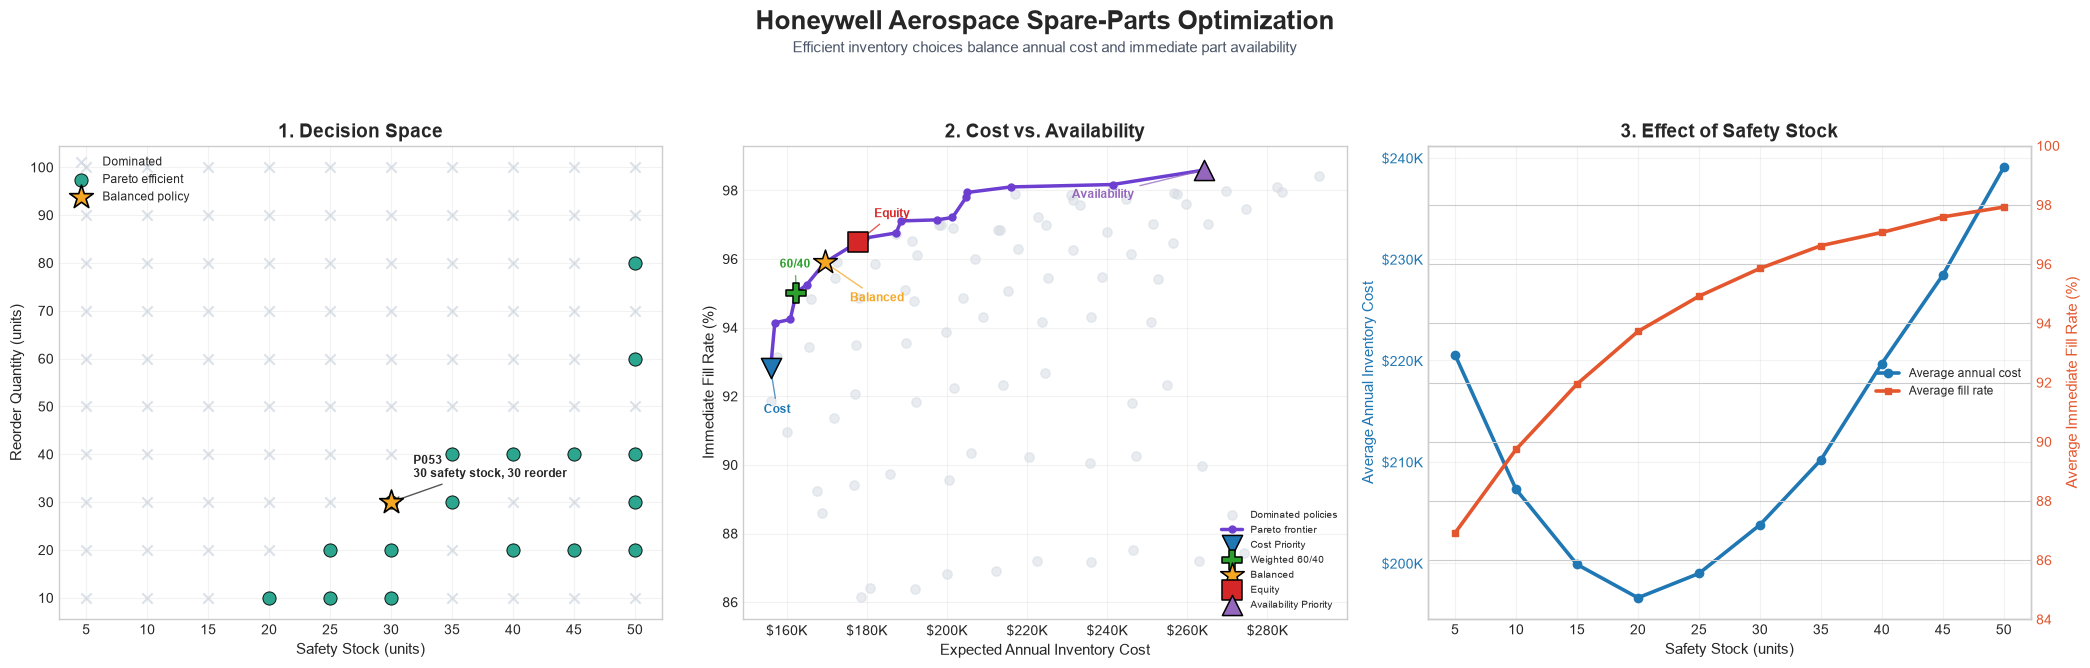

In [11]:
from matplotlib.ticker import FuncFormatter

plt.style.use("seaborn-v0_8-whitegrid")

fig, axes = plt.subplots(
    1,
    3,
    figsize=(21, 6.5),
)

# Consistent colors for strategic policies
strategy_plot_settings = [
    (
        "Cost Priority",
        cost_priority_idx,
        "#1F77B4",
        "v",
    ),
    (
        "Weighted 60/40",
        weighted_idx,
        "#2CA02C",
        "P",
    ),
    (
        "Balanced",
        balanced_idx,
        "#F5A623",
        "*",
    ),
    (
        "Equity",
        equity_idx,
        "#D62728",
        "s",
    ),
    (
        "Availability Priority",
        availability_priority_idx,
        "#9467BD",
        "^",
    ),
]

# Panel 1: Decision space
ax1 = axes[0]

ax1.scatter(
    dominated_df["safety_stock_units"],
    dominated_df["reorder_quantity_units"],
    s=55,
    color="#C9D2DC",
    marker="x",
    alpha=0.65,
    label="Dominated",
    zorder=1,
)

ax1.scatter(
    pareto_df["safety_stock_units"],
    pareto_df["reorder_quantity_units"],
    s=90,
    color="#159D82",
    edgecolors="black",
    linewidth=0.7,
    alpha=0.90,
    label="Pareto efficient",
    zorder=2,
)

ax1.scatter(
    strategic_df.loc[
        balanced_idx,
        "safety_stock_units",
    ],
    strategic_df.loc[
        balanced_idx,
        "reorder_quantity_units",
    ],
    s=320,
    color="#F5A623",
    marker="*",
    edgecolors="black",
    linewidth=1.2,
    label="Balanced policy",
    zorder=4,
)

ax1.annotate(
    "P053\n30 safety stock, 30 reorder",
    (
        strategic_df.loc[
            balanced_idx,
            "safety_stock_units",
        ],
        strategic_df.loc[
            balanced_idx,
            "reorder_quantity_units",
        ],
    ),
    xytext=(16, 18),
    textcoords="offset points",
    fontsize=8.5,
    fontweight="bold",
    arrowprops={
        "arrowstyle": "->",
        "color": "#555555",
    },
)

ax1.set_title(
    "1. Decision Space",
    fontsize=14,
    fontweight="bold",
)
ax1.set_xlabel("Safety Stock (units)", fontsize=11)
ax1.set_ylabel("Reorder Quantity (units)", fontsize=11)
ax1.set_xticks(range(5, 51, 5))
ax1.set_yticks(range(10, 101, 10))
ax1.grid(alpha=0.25)
ax1.legend(fontsize=8.5, loc="upper left")

# Panel 2: Objective space and Pareto frontier
ax2 = axes[1]

ax2.scatter(
    dominated_df[COST_COLUMN],
    dominated_df[AVAILABILITY_COLUMN],
    s=45,
    color="#D6DCE3",
    alpha=0.55,
    label="Dominated policies",
    zorder=1,
)

frontier_sorted = pareto_df.sort_values(COST_COLUMN)

ax2.plot(
    frontier_sorted[COST_COLUMN],
    frontier_sorted[AVAILABILITY_COLUMN],
    color="#6C3FD1",
    linewidth=2.5,
    marker="o",
    markersize=5,
    label="Pareto frontier",
    zorder=2,
)

annotation_offsets = {
    "Cost Priority": (-5, -32),
    "Weighted 60/40": (-12, 18),
    "Balanced": (18, -28),
    "Equity": (12, 18),
    "Availability Priority": (-95, -20),
}

short_labels = {
    "Cost Priority": "Cost",
    "Weighted 60/40": "60/40",
    "Balanced": "Balanced",
    "Equity": "Equity",
    "Availability Priority": "Availability",
}

for strategy_name, idx, color, marker in (
    strategy_plot_settings
):
    strategy_row = strategic_df.loc[idx]

    ax2.scatter(
        strategy_row[COST_COLUMN],
        strategy_row[AVAILABILITY_COLUMN],
        s=210 if marker != "*" else 320,
        color=color,
        marker=marker,
        edgecolors="black",
        linewidth=1.1,
        label=strategy_name,
        zorder=5,
    )

    ax2.annotate(
        short_labels[strategy_name],
        (
            strategy_row[COST_COLUMN],
            strategy_row[AVAILABILITY_COLUMN],
        ),
        xytext=annotation_offsets[strategy_name],
        textcoords="offset points",
        fontsize=8.5,
        fontweight="bold",
        color=color,
        arrowprops={
            "arrowstyle": "-",
            "color": color,
            "alpha": 0.75,
        },
    )

ax2.set_title(
    "2. Cost vs. Availability",
    fontsize=14,
    fontweight="bold",
)
ax2.set_xlabel(
    "Expected Annual Inventory Cost",
    fontsize=11,
)
ax2.set_ylabel(
    "Immediate Fill Rate (%)",
    fontsize=11,
)
ax2.xaxis.set_major_formatter(
    FuncFormatter(
        lambda value, position: f"${value / 1000:.0f}K"
    )
)
ax2.set_ylim(85.5, 99.3)
ax2.grid(alpha=0.25)
ax2.legend(
    fontsize=7.5,
    loc="lower right",
    framealpha=0.95,
)

# Panel 3: Both objectives by the primary decision variable
ax3 = axes[2]

safety_stock_summary = (
    df.groupby("safety_stock_units")
    .agg(
        average_cost=(
            COST_COLUMN,
            "mean",
        ),
        average_fill_rate=(
            AVAILABILITY_COLUMN,
            "mean",
        ),
    )
    .reset_index()
)

cost_line = ax3.plot(
    safety_stock_summary["safety_stock_units"],
    safety_stock_summary["average_cost"],
    color="#1F77B4",
    marker="o",
    linewidth=2.6,
    markersize=6,
    label="Average annual cost",
)

ax3.set_xlabel("Safety Stock (units)", fontsize=11)
ax3.set_ylabel(
    "Average Annual Inventory Cost",
    color="#1F77B4",
    fontsize=11,
)
ax3.tick_params(
    axis="y",
    labelcolor="#1F77B4",
)
ax3.yaxis.set_major_formatter(
    FuncFormatter(
        lambda value, position: f"${value / 1000:.0f}K"
    )
)
ax3.set_xticks(range(5, 51, 5))
ax3.grid(alpha=0.25)

ax3_right = ax3.twinx()

availability_line = ax3_right.plot(
    safety_stock_summary["safety_stock_units"],
    safety_stock_summary["average_fill_rate"],
    color="#E4572E",
    marker="s",
    linewidth=2.6,
    markersize=5,
    label="Average fill rate",
)

ax3_right.set_ylabel(
    "Average Immediate Fill Rate (%)",
    color="#E4572E",
    fontsize=11,
)
ax3_right.tick_params(
    axis="y",
    labelcolor="#E4572E",
)
ax3_right.set_ylim(84, 100)

combined_lines = cost_line + availability_line
combined_labels = [
    line.get_label()
    for line in combined_lines
]

ax3.legend(
    combined_lines,
    combined_labels,
    fontsize=8.5,
    loc="center right",
)

ax3.set_title(
    "3. Effect of Safety Stock",
    fontsize=14,
    fontweight="bold",
)

fig.suptitle(
    "Honeywell Aerospace Spare-Parts Optimization",
    fontsize=19,
    fontweight="bold",
    y=1.02,
)

fig.text(
    0.5,
    0.955,
    "Efficient inventory choices balance annual cost and immediate part availability",
    ha="center",
    fontsize=11,
    color="#4A5568",
)

plt.tight_layout(rect=[0, 0, 1, 0.93])

visualization_path = (
    Path("images") / "pareto_frontier_analysis.png"
)

plt.savefig(
    visualization_path,
    dpi=300,
    bbox_inches="tight",
    facecolor="white",
)

plt.show()